# 3. Modelos benchmark

Este capítulo cubre el Bloque B de la guía y la parte de benchmarks del Bloque D: qué modelos compiten contra el modelo original, cómo
se eligió la mejor combinación de cada familia entre las 140 del entregable anterior (con criterios estadísticos, no visuales), cómo se
serializaron para el dashboard y cómo quedan los 10 modelos (los 7 ganadores de familia, 2 métodos recientes del estado del arte y ELAR-R)
cuando se comparan en igualdad de condiciones. Las pruebas de hipótesis completas están en el capítulo 6.

El cuaderno solo lee resultados ya guardados (`resultados/`, `resultados_e4/`, `artifacts/`) y corre en segundos.

In [1]:
from pathlib import Path
import json
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, studentized_range

RAIZ = Path.cwd()                       # raiz del repositorio (sin rutas absolutas)
assert (RAIZ / "resultados" / "tabla_maestra.csv").is_file(), "Ejecute este cuaderno desde la raiz del repositorio"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
NOMBRE = {"elar": "ELAR-R (original)", "xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM",
          "logistica": "Regresion logistica", "svm": "SVM", "random_forest": "Random forest", "arbol": "Arbol de decision",
          "knn": "KNN", "naive_bayes": "Naive Bayes"}
tm = pd.read_csv(RAIZ / "resultados" / "tabla_maestra.csv")
clas = tm[tm["tarea"] == "clasificacion"].copy()
print(f"Combinaciones del E3: {len(tm)} ({len(clas)} de clasificacion = 7 modelos x 4 balanceos x 4 optimizadores)")

Combinaciones del E3: 140 (112 de clasificacion = 7 modelos x 4 balanceos x 4 optimizadores)


## 3.1 Los benchmarks

La tarea elegida es clasificación. Los benchmarks son los siete modelos base del E3 (cada uno en su mejor combinación) y dos métodos
recientes de *gradient boosting*, LightGBM {cite}`ke2017` y CatBoost {cite}`prokhorenkova2018catboost`, que la guía exige como
estado del arte y que, junto con XGBoost {cite}`chen2016`, siguen siendo la referencia en datos tabulares
{cite}`grinsztajn2022tree`.

In [2]:
# Tabla 3.1: definicion de los 9 benchmarks y su configuracion en la comparacion en igualdad (cap. 3.6)
final = json.loads((RAIZ / "resultados_e4" / "e10_igualdad" / "final.json").read_text(encoding="utf-8"))
filas = []
familias = {"naive_bayes": ("Probabilistico", "scikit-learn GaussianNB"), "arbol": ("Arbol", "scikit-learn DecisionTree"),
            "logistica": ("Lineal", "scikit-learn LogisticRegression"), "knn": ("Vecinos", "FAISS + PCA (propio, src/modelos.py)"),
            "svm": ("Nucleo", "Nystroem RBF + LinearSVC"), "random_forest": ("Ensamble bagging", "scikit-learn RandomForest"),
            "xgboost": ("Ensamble boosting", f"xgboost {version('xgboost')}"),
            "lightgbm": ("Boosting (estado del arte)", f"lightgbm {version('lightgbm')}"),
            "catboost": ("Boosting (estado del arte)", f"catboost {version('catboost')}")}
for m, (fam, lib) in familias.items():
    info = final.get(f"info_{m}", {})
    params = info.get("params")
    if m == "xgboost":
        params = json.loads((RAIZ / "experiments" / "params_comparador.json").read_text(encoding="utf-8"))
    if m in ("lightgbm", "catboost"):
        origen = "valores recomendados por los autores; hasta 2,000 rondas con parada temprana (50) en un 10 % interno"
        params = {"lightgbm": {"learning_rate": 0.05, "num_leaves": 31, "colsample_bytree": 0.8, "subsample": 0.8, "min_child_samples": 20},
                  "catboost": {"learning_rate": 0.05, "depth": 6, "l2_leaf_reg": 3.0}}[m]
    else:
        origen = f"ganador de familia del E3 ({info.get('balanceo', 'ninguno')} / {info.get('optimizador', 'genetica')})"
    filas.append({"modelo": NOMBRE[m], "familia": fam, "implementacion": lib, "origen de los hiperparametros": origen,
                  "hiperparametros": ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in (params or {}).items())})
pd.DataFrame(filas).set_index("modelo")

,familia,implementacion,origen de los hiperparametros,hiperparametros
modelo,,,,
Naive Bayes,Probabilistico,scikit-learn GaussianNB,ganador de familia del E3 (ninguno / genetica),var_smoothing=0.1
Arbol de decision,Arbol,scikit-learn DecisionTree,ganador de familia del E3 (ninguno / genetica),"max_depth=12, min_samples_leaf=782, max_featur..."
Regresion logistica,Lineal,scikit-learn LogisticRegression,ganador de familia del E3 (class_weight / baye...,"C=0.01784, penalizacion=l1"
KNN,Vecinos,"FAISS + PCA (propio, src/modelos.py)",ganador de familia del E3 (ninguno / rejilla),"n_vecinos=300, ponderacion=distance, n_compone..."
SVM,Nucleo,Nystroem RBF + LinearSVC,ganador de familia del E3 (class_weight / gene...,"C=4.909, nucleo=rbf_nystroem, gamma=0.0001"
Random forest,Ensamble bagging,scikit-learn RandomForest,ganador de familia del E3 (class_weight / alea...,"n_estimators=249, max_depth=16, min_samples_le..."
XGBoost,Ensamble boosting,xgboost 3.0.5,ganador de familia del E3 (ninguno / genetica),"learning_rate=0.0169, max_depth=6, min_child_w..."
LightGBM,Boosting (estado del arte),lightgbm 4.7.0,"valores recomendados por los autores; hasta 2,...","learning_rate=0.05, num_leaves=31, colsample_b..."
CatBoost,Boosting (estado del arte),catboost 1.2.10,"valores recomendados por los autores; hasta 2,...","learning_rate=0.05, depth=6, l2_leaf_reg=3"


## 3.2 Selección de la mejor combinación de cada familia

Criterio de la guía (sec. 4.1): para cada uno de los 7 modelos base, la combinación de balanceo y optimizador con mayor métrica media del
bucle externo de la validación anidada (AUC-ROC, 5 pliegues externos, 3 internos). La tabla 3.2 es la tabla maestra de la selección:
media ± desviación estándar, la segunda mejor combinación y la distancia entre ambas, que sirve para juzgar si la elección es clara o
un empate práctico.

In [3]:
sel = []
for m, g in clas.groupby("modelo"):
    g = g.sort_values("m_auc_roc_media", ascending=False)
    b, s = g.iloc[0], g.iloc[1]
    dif = b["m_auc_roc_media"] - s["m_auc_roc_media"]
    motivo = (f"mayor AUC externo medio de {len(g)} combinaciones; la segunda ({s['balanceo']}/{s['optimizador']}) queda a {dif:.4f}"
              + (" (menos de 1 desviacion estandar: empate practico)" if dif < b["m_auc_roc_sd"] else ""))
    sel.append({"modelo": NOMBRE[m], "balanceo": b["balanceo"], "optimizador": b["optimizador"],
                "AUC externo (media ± de)": f"{b['m_auc_roc_media']:.4f} ± {b['m_auc_roc_sd']:.4f}",
                "AUC media": b["m_auc_roc_media"], "peor combinacion": g["m_auc_roc_media"].min(),
                "horas de computo (16 comb.)": g["t_total_h"].sum(), "motivo": motivo, "_clave": f"{m}|{b['balanceo']}|{b['optimizador']}"})
sel = pd.DataFrame(sel).sort_values("AUC media", ascending=False).set_index("modelo")
sel.drop(columns="_clave").to_csv(RAIZ / "resultados_e4" / "seleccion_mejores_combinaciones.csv", encoding="utf-8")
sel.drop(columns=["_clave", "AUC media"]).round(4)

,balanceo,optimizador,AUC externo (media ± de),peor combinacion,horas de computo (16 comb.),motivo
modelo,,,,,,
XGBoost,ninguno,genetica,0.7721 ± 0.0038,0.7702,46.8457,mayor AUC externo medio de 16 combinaciones; l...
SVM,class_weight,genetica,0.7578 ± 0.0031,0.7425,153.9264,mayor AUC externo medio de 16 combinaciones; l...
Regresion logistica,class_weight,bayesiana,0.7576 ± 0.0028,0.7417,84.3424,mayor AUC externo medio de 16 combinaciones; l...
Random forest,class_weight,aleatoria,0.7497 ± 0.0035,0.7099,54.9094,mayor AUC externo medio de 16 combinaciones; l...
Arbol de decision,ninguno,genetica,0.6965 ± 0.0060,0.6500,11.7468,mayor AUC externo medio de 16 combinaciones; l...
KNN,ninguno,rejilla,0.6887 ± 0.0013,0.6597,35.7735,mayor AUC externo medio de 16 combinaciones; l...
Naive Bayes,ninguno,genetica,0.6464 ± 0.0019,0.5964,1.0377,mayor AUC externo medio de 16 combinaciones; l...


**Lectura de la tabla 3.2.** XGBoost es la mejor familia con amplio margen (0.772 frente a 0.758 de la siguiente). En las siete familias
la segunda combinación queda a 0.0008 o menos de la primera, muy por debajo de una desviación estándar entre pliegues: dentro de cada
familia la elección es un empate práctico, casi siempre entre optimizadores con el mismo balanceo. Lo que de verdad importa es el
balanceo: SMOTE y ADASYN empeoran a casi todos los modelos (cap. 06 del E3). La columna "peor combinación" muestra cuánto se pierde con una mala elección: hasta 0.05 de AUC en Naive Bayes y el árbol.

## 3.3 Mejor combinación global y finalistas de Friedman → Nemenyi

La guía pide verificar que la mejor combinación global pertenezca al conjunto de finalistas de la comparación estadística del entregable
anterior. Se recalcula aquí desde los AUC de las 112 combinaciones de clasificación en los 50 sub-bloques de validación externa
(`resultados/estudios/estadistica/bloques_clasificacion_auc_112.csv`): prueba de Friedman y diferencia crítica de Nemenyi
{cite}`demsar2006statistical`

$$
CD = q_{\alpha}\sqrt{\frac{k(k+1)}{6N}},
$$ (ec-cd)

con $k = 112$ combinaciones, $N = 50$ bloques y $q_{\alpha}$ el cuantil del rango estudentizado dividido por $\sqrt{2}$. Son finalistas las
combinaciones cuyo rango medio no difiere del de la mejor en más de $CD$.

In [4]:
B = pd.read_csv(RAIZ / "resultados" / "estudios" / "estadistica" / "bloques_clasificacion_auc_112.csv")
N, k = B.shape
rangos = B.rank(axis=1, ascending=False)            # 1 = mejor en el bloque
r_medio = rangos.mean().sort_values()
chi2, p_f = friedmanchisquare(*[B[c].to_numpy() for c in B.columns])
q = studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2)
CD = q * np.sqrt(k * (k + 1) / (6 * N))
mejor = r_medio.index[0]
finalistas = r_medio[r_medio - r_medio.iloc[0] <= CD]
global_tm = clas.sort_values("m_auc_roc_media", ascending=False).iloc[0]
clave_global = f"{global_tm['modelo']}|{global_tm['balanceo']}|{global_tm['optimizador']}"
print(f"Friedman: chi2 = {chi2:.1f}, p = {p_f:.1e} (N = {N} bloques, k = {k} combinaciones); CD de Nemenyi = {CD:.2f} rangos")
print(f"Mejor por rango medio: {mejor} ({r_medio.iloc[0]:.2f}); mejor por AUC externo medio: {clave_global}")
print(f"Finalistas (no distinguibles de la mejor): {len(finalistas)}; la mejor global por AUC es finalista: {clave_global in finalistas.index}")
ganadores = sel["_clave"]
tabla = pd.DataFrame({"rango medio": r_medio.reindex(ganadores.values).round(2).values,
                      "finalista": ganadores.isin(finalistas.index).values}, index=ganadores.index)
tabla

Friedman: chi2 = 5377.7, p = 0.0e+00 (N = 50 bloques, k = 112 combinaciones); CD de Nemenyi = 28.26 rangos
Mejor por rango medio: xgboost|ninguno|genetica (6.54); mejor por AUC externo medio: xgboost|ninguno|genetica
Finalistas (no distinguibles de la mejor): 32; la mejor global por AUC es finalista: True


,rango medio,finalista
modelo,,
XGBoost,6.54,True
SVM,23.10,True
Regresion logistica,23.50,True
Random forest,34.82,False
Arbol de decision,70.14,False
KNN,71.96,False
Naive Bayes,95.14,False


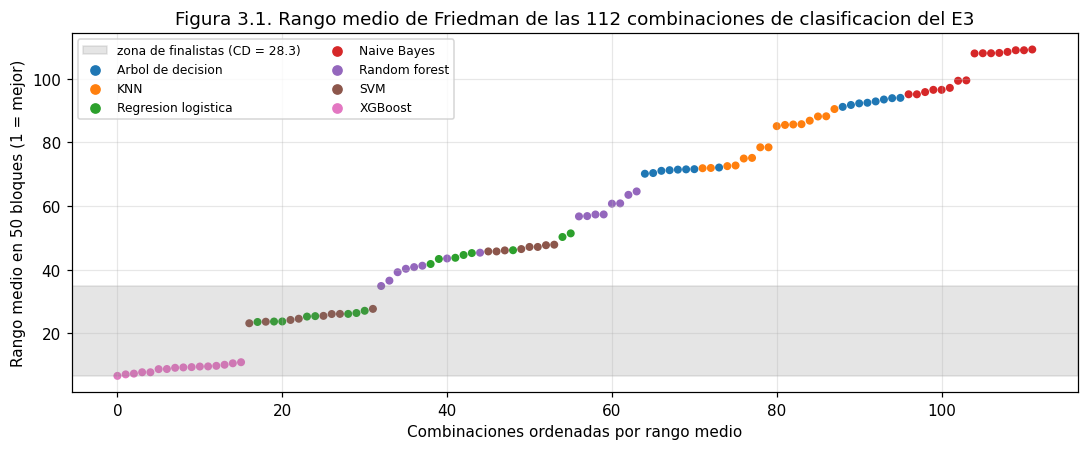

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
fam = [c.split("|")[0] for c in r_medio.index]
paleta = dict(zip(sorted(set(fam)), plt.cm.tab10.colors))
ax.scatter(range(k), r_medio.values, c=[paleta[f] for f in fam], s=18)
ax.axhspan(r_medio.iloc[0], r_medio.iloc[0] + CD, color="grey", alpha=0.2, label=f"zona de finalistas (CD = {CD:.1f})")
for f, col in paleta.items():
    ax.scatter([], [], c=[col], label=NOMBRE[f])
ax.set(title="Figura 3.1. Rango medio de Friedman de las 112 combinaciones de clasificacion del E3",
       xlabel="Combinaciones ordenadas por rango medio", ylabel="Rango medio en 50 bloques (1 = mejor)")
ax.legend(ncol=2, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Lectura de la figura 3.1 y la tabla 3.3.** Las combinaciones de XGBoost ocupan los primeros rangos. La mejor combinación global
(XGBoost sin balanceo con optimización genética) es la misma por AUC externo medio y por rango medio, y es finalista, como pide la guía.
Con 112 combinaciones la diferencia crítica es grande (28 rangos) y 32 combinaciones no se distinguen de la mejor. Entre los ganadores de
familia, SVM y logística quedan dentro de esa zona; random forest, árbol, KNN y Naive Bayes quedan fuera. Por eso el dashboard muestra los
siete pero señala esa diferencia.

## 3.4 Presupuesto de ajuste

Para que la comparación sea justa, todos los modelos reciben el mismo presupuesto dentro de cada experimento (tabla 3.4). En el E3 cada
combinación tuvo 20 evaluaciones de su optimizador con 3 pliegues internos en cada uno de los 5 pliegues externos. En la comparación del
E4 en Home Credit el presupuesto es **cero para todos**: ningún modelo se vuelve a ajustar sobre las 528 entradas (sec. 8.2 del
protocolo). En los conjuntos adicionales los 10 reciben TPE {cite}`bergstra2011algorithms` con 20 evaluaciones y 3 pliegues internos.

In [6]:
tme = pd.read_csv(RAIZ / "resultados_e4" / "tabla_maestra_e4.csv", low_memory=False)
adic = tme[tme["fuente"].astype(str).str.startswith("E4 conjuntos")]
t_adic = adic.groupby(["modelo", "conjunto"])["t_total_s"].sum().unstack() / 3600
pres = pd.DataFrame({
    "E3: evaluaciones por combinacion (20 x 5 pliegues)": clas.groupby("modelo")["evaluaciones_total"].max(),
    "E3: horas (16 combinaciones)": clas.groupby("modelo")["t_total_h"].sum(),
    "E4 Home Credit: evaluaciones": 0,
    "E4 adicionales: evaluaciones por pliegue": 20,
    "E4 adicionales: horas (3 conjuntos)": t_adic.sum(axis=1),
}).rename(index=NOMBRE)
pres.loc[["LightGBM", "CatBoost", "ELAR-R (original)"], ["E3: evaluaciones por combinacion (20 x 5 pliegues)", "E3: horas (16 combinaciones)"]] = np.nan
pres.round(2)

,E3: evaluaciones por combinacion (20 x 5 pliegues),E3: horas (16 combinaciones),E4 Home Credit: evaluaciones,E4 adicionales: evaluaciones por pliegue,E4 adicionales: horas (3 conjuntos)
modelo,,,,,
Arbol de decision,100.0,11.75,0,20,0.06
CatBoost,NaN,NaN,0,20,7.42
ELAR-R (original),NaN,NaN,0,20,10.85
KNN,100.0,35.77,0,20,0.51
LightGBM,NaN,NaN,0,20,2.08
Regresion logistica,100.0,84.34,0,20,0.60
Naive Bayes,100.0,1.04,0,20,0.01
Random forest,100.0,54.91,0,20,0.68
SVM,100.0,153.93,0,20,0.45


**Lectura de la tabla 3.4.** El presupuesto en número de evaluaciones es idéntico para todos dentro de cada experimento; lo que cambia
es el tiempo que cuesta cada evaluación. ELAR-R es el modelo más caro en los conjuntos adicionales (su ajuste es iterativo y entrena
tres vistas), seguido de CatBoost; Naive Bayes y el árbol cuestan segundos. Los tiempos completos por modelo están en el capítulo 7 y en
la tabla maestra (`resultados_e4/tabla_maestra_e4.csv`).

## 3.5 Reentrenamiento final y artefactos

Cada ganador de familia se reentrenó en el E3 con todo el desarrollo y sus hiperparámetros finales. En el E4 se le unió el
preprocesador (ajustado sobre el mismo desarrollo) en un único objeto `ModeloRiesgo` (`src/artefactos.py`), de modo que el dashboard
recibe las columnas crudas y nunca reentrena ni optimiza. ELAR-R se ajustó con todo el desarrollo y sus 83 variables. Cada artefacto
pasa una prueba de ida y vuelta: el puntaje sobre la prueba coincide con el guardado por el experimento y, tras `joblib.dump` y
`joblib.load`, con el del objeto en memoria (`tests/test_artefactos.py`).

In [7]:
meta = json.loads((RAIZ / "artifacts" / "metadata.json").read_text(encoding="utf-8"))
art = pd.DataFrame({m: {"AUC prueba": v["auc_prueba_artefacto"], "dif. max. vs experimento": v["dif_max_vs_guardado"],
                        "dif. max. ida y vuelta": v["dif_max_ida_vuelta"], "tamano (MB)": v["tamano_mb"],
                        "inferencia prueba (s)": v["t_inferencia_prueba_s"], "umbral de coste": v["umbral_coste"]}
                    for m, v in meta.items() if not m.startswith("_")}).T
art = art.rename(index={**NOMBRE, "elar_r": "ELAR-R (original, + 83 variables)"}).sort_values("AUC prueba", ascending=False)
print("Versiones:", ", ".join(f"{k} {v}" for k, v in meta["_versiones"].items()))
print(f"Tamano total: {art['tamano (MB)'].sum():.1f} MB (ninguno supera el limite de 100 MB por archivo de GitHub)")
art

Versiones: python 3.12.0, numpy 2.2.6, scipy 1.15.3, pandas 2.3.3, sklearn 1.7.2, xgboost 3.0.5, joblib 1.5.2, faiss 1.12.0
Tamano total: 73.7 MB (ninguno supera el limite de 100 MB por archivo de GitHub)


,AUC prueba,dif. max. vs experimento,dif. max. ida y vuelta,tamano (MB),inferencia prueba (s),umbral de coste
"ELAR-R (original, + 83 variables)",0.789941,0.0,0.0,16.19,45.728124,"interno de ELAR-R (criterio_umbral='coste', FN..."
XGBoost,0.775379,0.0,0.0,1.34,2.921845,0.08937
Regresion logistica,0.759739,0.0,0.0,0.03,1.910988,0.522136
SVM,0.759489,0.0,0.000224,1.27,4.10321,0.029369
Random forest,0.754437,0.0,0.0,15.17,2.851906,0.384142
Arbol de decision,0.701746,0.0,0.0,0.04,1.722947,0.091707
KNN,0.69755,0.0,0.0,39.63,9.464585,0.090405
Naive Bayes,0.647718,0.0,0.0,0.04,3.013593,0.943936


**Lectura de la tabla 3.5.** Las diferencias de ida y vuelta son cero o del orden de $10^{-7}$; en SVM llegan a $2 \times 10^{-4}$
en el puntaje de decisión (no es una probabilidad) por el redondeo de BLAS al procesar la prueba en bloques de distinto tamaño, y no
cambian ninguna decisión. La prueba unitaria usa esa tolerancia y lo documenta. Ojo: estos artefactos son los modelos **del E3 con sus
entradas** (y ELAR-R con sus 83 variables), que es lo que usa el dashboard para predecir; la comparación científica en igualdad de
condiciones es la de la sección 3.6.

## 3.6 Los 10 modelos en igualdad de condiciones

Esta es la comparación que sustenta el veredicto sobre R3 (protocolo, secs. 6.5 y 8.2): los 10 modelos con las mismas 528 entradas, los
mismos 5 pliegues externos del E3, la misma prueba de 61,503 filas y el mismo presupuesto de búsqueda (cero).

In [8]:
pe = json.loads((RAIZ / "resultados_e4" / "e10_igualdad" / "pruebas_elar.json").read_text(encoding="utf-8"))
modelos = pe["modelos"]
rm = dict(zip(modelos, pe["friedman"]["rangos_medios"]))
igual = pd.DataFrame({m: {"AUC pliegues (media)": np.mean(pe["auc_por_pliegue"][m]), "de": np.std(pe["auc_por_pliegue"][m], ddof=1),
                          "AUC OOF (246,008)": pe["auc_oof"][m], "AUC prueba (61,503)": pe["auc_prueba_final"][m],
                          "rango medio (50 bloques)": rm[m]} for m in modelos}).T
for m, c in pe["comparaciones_elar_vs"].items():
    igual.loc[m, "ELAR-R - modelo (OOF)"] = c["dif_oof"]
    igual.loc[m, "IC 95 % BCa"] = f"[{c['ic95_bca'][0]:+.4f}, {c['ic95_bca'][1]:+.4f}]"
    igual.loc[m, "pruebas significativas (Holm, de 4)"] = c["significativas_holm"]
    igual.loc[m, "veredicto"] = c["veredicto"]
igual = igual.sort_values("AUC OOF (246,008)", ascending=False).rename(index=NOMBRE)
f = pe["friedman"]
print(f"Friedman (10 modelos, 50 bloques): chi2 = {f['chi2']:.1f}, p = {f['p']:.1e}; Iman-Davenport F = {f['F_iman_davenport']:.1f}")
igual.round(4)

Friedman (10 modelos, 50 bloques): chi2 = 414.5, p = 1.1e-83; Iman-Davenport F = 571.6


,AUC pliegues (media),de,"AUC OOF (246,008)","AUC prueba (61,503)",rango medio (50 bloques),ELAR-R - modelo (OOF),IC 95 % BCa,"pruebas significativas (Holm, de 4)",veredicto
XGBoost,0.7877,0.0040,0.7877,0.7902,1.60,-0.0039,"[-0.0048, -0.0030]",4.0,NO SUPERA
CatBoost,0.7843,0.0047,0.7843,0.7898,2.88,-0.0005,"[-0.0015, +0.0003]",1.0,NO SUPERA
ELAR-R (original),0.7838,0.0038,0.7838,0.7871,2.70,NaN,NaN,NaN,NaN
LightGBM,0.7835,0.0035,0.7835,0.7867,3.08,0.0003,"[-0.0007, +0.0014]",0.0,NO SUPERA
Regresion logistica,0.7738,0.0034,0.7738,0.7765,5.20,0.0100,"[+0.0090, +0.0110]",4.0,SUPERA
SVM,0.7725,0.0034,0.7725,0.7753,5.84,0.0113,"[+0.0102, +0.0124]",4.0,SUPERA
Random forest,0.7657,0.0042,0.7656,0.7694,6.70,0.0182,"[+0.0169, +0.0195]",4.0,SUPERA
Arbol de decision,0.7195,0.0046,0.7197,0.7253,8.10,0.0641,"[+0.0618, +0.0668]",4.0,SUPERA
KNN,0.6993,0.0018,0.6992,0.7045,8.90,0.0846,"[+0.0814, +0.0876]",4.0,SUPERA
Naive Bayes,0.6590,0.0030,0.6585,0.6579,10.00,0.1253,"[+0.1212, +0.1289]",4.0,SUPERA


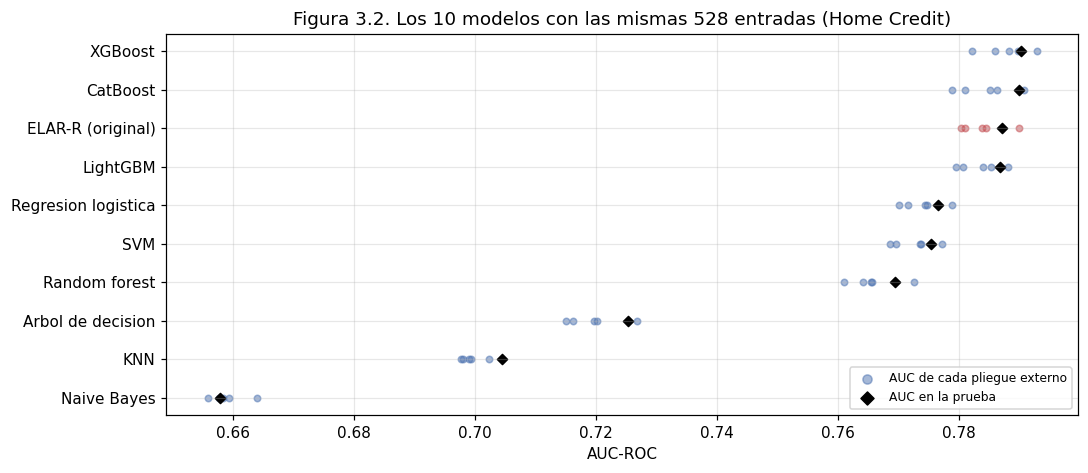

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.4))
orden = [m for m in sorted(modelos, key=lambda m: pe["auc_oof"][m])]
for i, m in enumerate(orden):
    v = pe["auc_por_pliegue"][m]
    col = "#C44E52" if m == "elar" else "#4C72B0"
    ax.scatter(v, [i] * len(v), color=col, alpha=0.5, s=18)
    ax.scatter(pe["auc_prueba_final"][m], i, marker="D", color="k", s=22)
ax.set_yticks(range(len(orden)), [NOMBRE[m] for m in orden])
ax.scatter([], [], color="#4C72B0", alpha=0.5, label="AUC de cada pliegue externo")
ax.scatter([], [], marker="D", color="k", label="AUC en la prueba")
ax.set(title="Figura 3.2. Los 10 modelos con las mismas 528 entradas (Home Credit)", xlabel="AUC-ROC")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Lectura de la tabla 3.6 y la figura 3.2.** Los cuatro modelos de boosting forman un grupo de cabeza separado del resto por casi 0.01
de AUC. Dentro de ese grupo, XGBoost es mejor que ELAR-R en las cuatro pruebas tras Holm (−0.0039 fuera de muestra, IC BCa enteramente
negativo), mientras que con CatBoost y LightGBM la diferencia es de unas milésimas y no es significativa (empate, hipótesis H3). ELAR-R
supera con claridad a los otros seis ganadores de familia. El patrón es estable: los AUC por pliegue y el de la prueba mantienen casi el mismo
orden, y en 9 de los 10 modelos la prueba queda algo por encima de la media de los pliegues, porque el modelo final se entrena con el
100 % del desarrollo en lugar del 80 %.